[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/protocols/agentic_mimicking_protocols/LLMWorkflow1/LLM_Workflow_Protocol.ipynb)

# EduAll Foundation — Grant Call 2026
## Group Project Report: LLM Workflow (Human-AI condition)

**Protocol:** `protocols/humanAI_LLMworkflow.pdf` — a multi-step pipeline in which an LLM performs a sequence of
distinct sub-tasks rather than a single judging call.
**Group:** Group LLM-1, four students (A, B, C, D).
**Input data:** `data/EduAll_500_Applications_Dataset.csv` (structured facts) and the 500 natural-text application files
in `data/individual_applications/` (the narrative evidence).
**Model:** Google Gemini (`gemini-3.5-flash-lite`, temperature 0, JSON output with a schema), called from this notebook.

Our design principle is **arithmetic in code, judgement in the LLM**. Code does what must be exact and reproducible:
the budget arithmetic, the gate, the weighted score, retrieving the peers and the allocation. The LLM does what needs
reading: eligibility evidence hidden in the narrative, scoring need and merit from the documents, and drafting a
recommendation with a rationale. Every LLM step reads the **full application document together with the CSV row**,
and it **enriches the CSV** with new columns extracted from the text (for example whether support ends in 2027/28, or
whether the document contradicts the CSV).

This notebook **is** our project report. It follows the protocol's four steps:

1. **Anchor the workflow's steps**: every step maps to a citable requirement of the call.
2. **Design the step sequence**: five steps, the code/LLM split, and where the human checkpoint sits.
3. **Build and run**: every applicant goes through every step, and every step's output is logged
   (`workflow_log.jsonl`).
4. **Documentation and reproducibility**: prompts and settings published, a 16% re-run with per-step agreement,
   and the human checkpoint stated.

Each step also has a **🧩 In AnythingLLM** box. It explains how to build the same step without code, as an
**AnythingLLM Agent Flow** (the protocol's no-code option). At the end, the notebook writes an importable flow
skeleton, `anythingllm_flow_eduall.json`.

> **About the first run shipped with this notebook.** The results, CSV exports and HTML of the first execution were
> produced with **Claude (Opus 5.5) acting as the LLM endpoint**: it read each prompt below and returned the JSON the
> schema asks for, exactly as Gemini would. Those responses are stored in `llm_responses_firstrun.jsonl`, keyed by
> applicant, step and a hash of the exact prompt. Without an API key the notebook **replays** them, so you can study
> the whole pipeline at no cost. With a `GEMINI_API_KEY` secret it calls **Gemini live**. That is the run your
> group reports. If you change any prompt or rule, replay stops for the changed steps, and you must run live.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "protocols/agentic_mimicking_protocols/LLMWorkflow1"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

### How to run this notebook on Google Colab

1. Upload this notebook to Colab (*File → Upload notebook*).
2. Get a free API key at [Google AI Studio](https://aistudio.google.com/apikey).
3. In Colab, click the **🔑 (Secrets)** icon in the left sidebar → **Add new secret** → Name `GEMINI_API_KEY`, Value:
   your key → switch on **Notebook access**. The key never appears in the notebook or its outputs.
4. *Runtime → Run all.* When the data cell asks, upload `EduAll_500_Applications_Dataset.csv` and
   `individual_applications.zip`. To replay the documented first run instead, also upload
   `llm_responses_firstrun.jsonl` and do not add the secret.

A full live run makes about 1,460 calls (500 + 379 + 379 for the three LLM steps, plus 202 for the re-run). At 10
requests per minute this takes about 2.5 hours. If the free tier's **daily** quota stops the run, the notebook keeps
everything done so far in `llm_responses.jsonl`. Run the cells again the next day and only the missing calls are made.
Download `llm_responses.jsonl` before closing Colab, because Colab's disk is temporary.

In [1]:
# --- Setup: packages, imports, settings -------------------------------------------------
import importlib.util, subprocess, sys
if importlib.util.find_spec("google.genai") is None:            # e.g. on Google Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "google-genai"], check=True)

import hashlib, json, os, pathlib, re, time, zipfile, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

# ---- Model settings (published as required by Step 4 of the protocol) ----
MODEL = "gemini-3.5-flash-lite"   # Gemini 3.6+ models ignore `temperature`; 3.5 Flash-Lite still honours it
TEMPERATURE = 0.0                 # as deterministic as the API allows
SEED = 2026                       # sampling seed passed to the API, and seed for the re-run sample
MAX_OUTPUT_TOKENS = 2048
REQUESTS_PER_MINUTE = 10          # free-tier friendly; raise it if your quota allows
RERUN_SHARE = 0.16                # protocol: re-run 15-20% of applicants
RUN_TAG = "run1"

The settings above are part of what Step 4 asks us to publish. We use **temperature 0** and a fixed **seed**, which
makes the model as repeatable as the API allows. It is not perfectly deterministic, and that is why we re-run a
sample in Step 4. We chose `gemini-3.5-flash-lite` because the newer Gemini generations (3.6 and later) ignore the
temperature setting. A model whose randomness we cannot set is not a good basis for a reproducible workflow.

In [2]:
# --- API key: declared as a Colab secret, never written in the notebook ----------------------
# In Colab: click the key icon in the left sidebar -> "Add new secret" -> Name: GEMINI_API_KEY,
# Value: your key from https://aistudio.google.com/apikey -> switch on "Notebook access".
GEMINI_API_KEY = None
try:
    from google.colab import userdata                  # only exists on Colab
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")  # local alternative: an environment variable

# Where responses come from:
#  * "gemini": live calls (needs the key). Every response is cached in llm_responses.jsonl, so an interrupted run
#    (e.g. daily quota reached) continues where it stopped when you re-run the cells.
#  * "replay": re-use the responses stored in llm_responses_firstrun.jsonl (the documented first run shipped with
#    this notebook). Only possible while the prompts are unchanged: any change to a prompt or rule makes replay stop.
BACKEND = "gemini" if GEMINI_API_KEY else "replay"
print("backend:", BACKEND, "| model:", MODEL if BACKEND == "gemini" else "(stored first-run responses)")

backend: replay | model: (stored first-run responses)


In [3]:
# --- Data: course folder or Colab upload ----------------------------------------------------
CANDIDATES = [pathlib.Path("../../../../data"), pathlib.Path("../../../data"), pathlib.Path("data"), pathlib.Path(".")]
DATA = next((b for b in CANDIDATES if (b / "EduAll_500_Applications_Dataset.csv").exists()), None)
if DATA is None:
    from google.colab import files
    print("Upload EduAll_500_Applications_Dataset.csv and individual_applications.zip")
    files.upload()
    DATA = pathlib.Path(".")
APPS = DATA / "individual_applications"
if not APPS.exists() and (DATA / "individual_applications.zip").exists():
    with zipfile.ZipFile(DATA / "individual_applications.zip") as z:
        z.extractall(DATA)
df = pd.read_csv(DATA / "EduAll_500_Applications_Dataset.csv", keep_default_na=False).set_index("student_id", drop=False)
df.index.name = None
raw_docs = {sid: (APPS / f"{sid}_application.md").read_text(encoding="utf-8") for sid in df.student_id}
print(df.shape, "| application files:", len(raw_docs))

(500, 44) | application files: 500


---
## Step 1 — Anchor the workflow's steps

*Budget: ~16.2h for a 4-student group.*

We read the foundation's **Organization Profile** and the **Grant Call 2026**, and the FAQ where the call refers to it.

**Mission (Organization Profile):** *"Our focus is not on academic excellence or competition, but rather on
identifying students with genuine financial need and providing them with the means to pursue their studies."*

### 1.1 Step-to-criteria mapping

Every step of the pipeline exists because a clause of the call requires it. Steps that touch a narrative criterion
take the application document as input, as the protocol requires.

| Pipeline step | What it does | Call requirement it implements | Who does it | Input |
|---|---|---|---|---|
| **1 Document intake** | joins each CSV row with the applicant's own application text; computes the 2027/28 shortfall, months of study inside the grant period, and progress | Grant period Sep 2027 – Aug 2028; "documented genuine financial need"; award caps per level (CHF 8,000 / 6,500 / 5,000) | code | CSV + document |
| **2 Eligibility extraction** | checks the 7 hard criteria H1–H7 and gates applicants out, with the reason logged | *Primary Eligibility Requirements* (7) and *Ineligible Categories* (Permit C with significant resources, distance learning, programmes < 1 year, previous EduAll grant) | H1, H3: code. H2, H4–H7: **LLM** (evidence often only in the narrative). Gate: code | CSV + document |
| **— Human checkpoint** | we decide every case the LLM flags | *"Each application is reviewed individually"*; pending-permit and GPA exceptions are case-by-case in the call | **humans (us)** | flagged files |
| **3 Need/merit read-out** | scores the 5 soft criteria S1–S5 with evidence and extracts 7 new CSV columns from the text | *Evaluation Criteria* and weights: need 40%, motivation 25%, resilience 20%, diversity 10%, values 5%; *Priority considerations* | **LLM** scores. Weighted score: code | CSV + document |
| **4 Peer comparison** | retrieves the 4 most comparable eligible applicants in the same cohort | Protocol: "comparable peers in this cohort" (no funding history exists); call's priority for low-income-country students | code (retrieval) | step 1 + 3 outputs |
| **5 Recommendation drafting** | calibrates the score against peers, assigns a category and writes a rationale | *Award decision* clause: individual review, written justification | **LLM** | steps 2–4 + record |
| **— Allocation** | turns recommendations into awards until CHF 500,000 is spent | Budget CHF 500,000; caps per study level; awards cover living costs only (non-fundable: childcare, family members, debt, travel home) | code | step 5 |

### 1.2 Hard criteria (pass/fail, n = 7) and our interpretation

| # | Call criterion | How we check it | Our group's interpretation |
|---|---|---|---|
| H1 | Non-Swiss citizen | `country_origin` (code) | all 500 are international: pass |
| H2 | Legally residing in Switzerland | LLM reads permit + document | B, C, F, S, L, G pass. **Pending → conditional** (the call: award conditional on the permit). **Permit C + supporting household ≥ CHF 6,000/month → fail** (our threshold for "significant family resources"). Renewal at risk → **flag** |
| H3 | Accredited Swiss institution | `university` (code) | all listed institutions are accredited: pass |
| H4 | Documented genuine financial need | LLM: CSV figures + document | pass if the 2027/28 shortfall > 0. If it is 0, pass only with **concrete document evidence** of a gap in 2027/28 (a job, scholarship or family support that ends) |
| H5 | Satisfactory standing (GPA ≥ 2.5, exceptions explained) | LLM: GPA + document | GPA < 2.5 → **conditional** only if the document explains the reasons *and* how the applicant is improving. Otherwise fail |
| H6 | Degree programme, not distance learning, ≥ 1 year | LLM | study-permit holders planning part-time study or > 15 h/week of work → **flag**. Doctoral applicants must explain why university funding is unavailable |
| H7 | Legal compliance; no EduAll grant in the last 2 years | LLM reads the document | any legal/immigration issue or previous grant → **flag** for a human |

### 1.3 Soft criteria (scored 0–10, n = 5)

| # | Call criterion (weight) | What the LLM looks for in the document |
|---|---|---|
| S1 | Financial need (40%) | shortfall ratio, savings, alternatives, and what changes in 2027/28. Non-fundable costs do not count |
| S2 | Academic motivation & potential (25%) | specific goals linked to the programme. GPA counts only as standing, not excellence (FAQ Q11) |
| S3 | Personal resilience & determination (20%) | adversity overcome and engagement *as described*. Ticked boxes alone are weak evidence |
| S4 | Contribution to diversity (10%) | +4 low-income country, +3 first-generation, +0–3 under-represented background in the text |
| S5 | Alignment with EduAll values (5%) | equal opportunity, giving back |

---
## Step 2 — Design the step sequence

*Budget: ~24.4h for a 4-student group.*

```
            ┌──────────────┐   ┌──────────────────┐   ┌───────────┐   ┌──────────────────┐   ┌───────────┐   ┌──────────────────┐   ┌────────────┐
 CSV row ──►│ 1 Intake     │──►│ 2 Eligibility    │──►│  HUMAN    │──►│ 3 Need/merit     │──►│ 4 Peers   │──►│ 5 Recommendation │──►│ Allocation │
 document ─►│ (code)       │   │ (LLM) + gate     │   │ CHECKPOINT│   │ read-out (LLM)   │   │ (code)    │   │ (LLM)            │   │ (code)     │
            └──────────────┘   └──────────────────┘   └───────────┘   └──────────────────┘   └───────────┘   └──────────────────┘   └────────────┘
                                  │ fail → out, reason logged            │ + 7 new CSV columns
```

**Design decisions:**

- **Three separate LLM sub-tasks, not one judging call.** Each has its own prompt, its own JSON schema, and its own
  log entry. A divergence can then be traced to the step where it started (Step 4 of the protocol asks for exactly
  this).
- **Structured output.** Each LLM call must return JSON that matches a schema, with an *evidence* field and a
  *source* (`csv`, `document`, `both`) for every verdict. The output can be checked and can go straight into CSV
  columns.
- **The gate is code.** The LLM gives verdicts. A fixed rule turns them into *eligible / conditional / human checkpoint /
  ineligible*. The LLM can say "flag" but cannot decide a flagged case.
- **Human checkpoint between steps 2 and 3.** Every applicant with a *flag* verdict is read in full by two of us
  before anything else happens.
- **Peers are retrieved by code.** The dataset has no funding history, so "comparable past decisions" becomes the
  4 most similar eligible applicants in the same cohort (same GNI tier and same study level, closest shortfall
  ratio). They reach the LLM in step 5 as calibration context.
- **Everything is logged.** One line per applicant and step in `workflow_log.jsonl`: time, step, prompt hash,
  producer and the full output.

<div style="border-left:4px solid #7b61ff;background:#f6f4ff;padding:10px 14px;margin:6px 0">

**🧩 In AnythingLLM — the overall design**

AnythingLLM's no-code builder is called **Agent Flows** (open a workspace's *Agent Skills* page → **Create Flow**). A
new flow has three default blocks: **Flow Information** (name, description), **Flow Variables** (the inputs) and
**Flow Complete**. With **Add Block** you insert, among others:

- **LLM Instruction**: *Instructions* (the prompt) and a *Result Variable* that stores the answer,
- **API Call**: URL, Method, Headers, Body, Result Variable,
- **Web Scraper**,
- **Read File / Write File**: Desktop app v1.8.1 or later only, with `${variable}` allowed in the file path.

Any field can use `${variableName}` to insert a variable or an earlier block's result. When a result is JSON, a path
such as `${eligibility.H2.verdict}` reaches inside it. The LLM used is the one set for the workspace and its agent.
**Google Gemini** is one of the supported providers, so the same model and temperature can be used there. A flow runs
when you call the agent in a workspace chat (`@agent …`). The agent fills the flow's variables from your message.

Our mapping: **one flow = one applicant through steps 2, 3 and 5** (three LLM Instruction blocks). Steps 1, 4 and the
allocation are arithmetic, which a no-code flow cannot do reliably. They become **inputs** (Flow Variables)
prepared in a spreadsheet or by this notebook, or an **API Call** block to a small service.

**Two limitations to know** (as of October 2026):

- **No loop block.** A flow handles one applicant per run. To process 500 applicants, run the flow once per applicant,
  or send one chat message per applicant through the AnythingLLM developer API from a short script.
- **No if/else block.** A loop and conditional logic are an open feature request
  ([anything-llm issue #6445](https://github.com/Mintplex-Labs/anything-llm/issues/6445)). Our gate ("stop if
  ineligible") is therefore written into the next prompt: *"If any verdict is fail, answer {"skipped": true}"*.
</div>

---
## Step 3 — Build and run

*Budget: ~81.2h for a 4-student group, the bulk of the phase.*

We chose the **code option** (a Python pipeline with an explicit state, the DataFrame `df`, passed from step to step)
so that every applicant runs through every step and is logged automatically. The 🧩 boxes give the no-code equivalent
step by step.

### 3.0 The LLM call

One function, `llm_json`, makes every LLM call. It sends the system instruction and the step's prompt, requires JSON
that matches the step's schema, and retries on rate limits. It **caches** each response under
`run | step | applicant` together with a hash of the exact prompt. A stopped run therefore continues where it stopped,
and a changed prompt is never answered from an old response.

In [4]:
# --- The LLM call: JSON output, cache/resume, per-step log --------------------------------
OUT = pathlib.Path(".")
CACHE_FILE, FIRSTRUN_FILE, LOG_FILE = OUT / "llm_responses.jsonl", OUT / "llm_responses_firstrun.jsonl", OUT / "workflow_log.jsonl"

def _load(path):
    d = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                r = json.loads(line); d[r["key"]] = r
    return d
CACHE = _load(CACHE_FILE) if BACKEND == "gemini" else _load(FIRSTRUN_FILE)
print(f"responses available in cache: {len(CACHE)}")

def prompt_hash(system, user, schema):
    return hashlib.sha256((system + "\n" + user + "\n" + json.dumps(schema, sort_keys=True)).encode()).hexdigest()[:16]

class QuotaExhausted(Exception):
    pass

_client, _last_call = None, [0.0]
def _gemini(system, user, schema):
    global _client
    from google import genai
    from google.genai import types
    if _client is None:
        _client = genai.Client(api_key=GEMINI_API_KEY)
    cfg = dict(system_instruction=system, temperature=TEMPERATURE, seed=SEED, max_output_tokens=MAX_OUTPUT_TOKENS,
               response_mime_type="application/json")
    try:
        config = types.GenerateContentConfig(**cfg, response_json_schema=schema)
    except Exception:                                      # older google-genai versions (no response_json_schema)
        config = types.GenerateContentConfig(**cfg, response_schema=schema)
    for attempt in range(6):
        wait = 60.0 / REQUESTS_PER_MINUTE - (time.time() - _last_call[0])
        if wait > 0: time.sleep(wait)
        _last_call[0] = time.time()
        try:
            r = _client.models.generate_content(model=MODEL, contents=user, config=config)
            return json.loads(r.text)
        except json.JSONDecodeError:
            continue                                       # malformed JSON: ask again
        except Exception as e:
            msg = str(e)
            if "per day" in msg.lower() or "PerDay" in msg:
                raise QuotaExhausted("Daily quota reached. Re-run this cell tomorrow: cached steps are not repeated.")
            if "429" in msg or "RESOURCE_EXHAUSTED" in msg or "503" in msg:
                time.sleep(20 * (attempt + 1)); continue
            raise
    raise RuntimeError("Gemini did not return valid JSON after 6 attempts")

def llm_json(step, sid, system, user, schema, run=None):
    """One LLM sub-task for one applicant. Returns the parsed JSON response and logs it."""
    run = run or RUN_TAG
    key, h = f"{run}|{step}|{sid}", prompt_hash(system, user, schema)
    hit = CACHE.get(key)
    if hit and hit["prompt_hash"] == h:
        resp, producer = hit["response"], hit.get("producer", MODEL)
    elif BACKEND == "replay":
        raise RuntimeError(f"{key}: no stored response for this exact prompt. The prompts were changed, "
                           "so add a GEMINI_API_KEY secret and run live.")
    else:
        resp, producer = _gemini(system, user, schema), MODEL
        rec = {"key": key, "prompt_hash": h, "producer": producer, "response": resp}
        CACHE[key] = rec
        with CACHE_FILE.open("a", encoding="utf-8") as f: f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    with LOG_FILE.open("a", encoding="utf-8") as f:
        f.write(json.dumps({"time": datetime.now(timezone.utc).isoformat(timespec="seconds"), "run": run, "step": step,
                            "student_id": sid, "prompt_hash": h, "producer": producer, "output": resp}, ensure_ascii=False) + "\n")
    return resp

def run_step(step, ids, build, schema, run=None, label=""):
    """Run one step over many applicants; stops cleanly (keeping everything done so far) if the quota ends."""
    out = {}
    try:
        for i, sid in enumerate(ids, 1):
            system, user = build(sid)
            out[sid] = llm_json(step, sid, system, user, schema, run)
            if i % 50 == 0: print(f"  {label or step}: {i}/{len(ids)}")
    except QuotaExhausted as e:
        print(f"STOPPED after {len(out)} of {len(ids)} applicants: {e}")
    return out
LOG_FILE.unlink(missing_ok=True)       # a fresh per-step log for this execution

responses available in cache: 1460


### 3.1 Pipeline step 1 — Document intake (code)

For each applicant we build the **record** that every LLM step sees. It has three parts:

- the CSV row,
- figures derived in code: `need_2027` (expected monthly shortfall in 2027/28), `shortfall_ratio`,
  `months_in_grant` (months of study inside Sep 2027 – Aug 2028, from the completion date written in the file),
  `months_to_completion` and `progress`,
- the **full application document** as the applicant submitted it.

The portal's footer (the section with the selection outcome) is removed so that the model cannot see it.

In [5]:
# --- Step 1: Document intake --------------------------------------------------------------
# Arithmetic happens in code (it must be exact and reproducible); judgement happens in the LLM steps.
CAP = {"Bachelor's": 8000, "Master's": 6500, "Doctoral": 5000}
REQUIRED = {"Bachelor's": 40, "Master's": 12, "Doctoral": 12}
MONTH = {"January": 1, "July": 7}
def completion(text):
    m = re.search(r"\*\*Expected Completion:\*\*\s*(January|July) (\d{4})", text)
    return (int(m.group(2)), MONTH[m.group(1)]) if m else (None, None)
df["completion_year"], df["completion_month"] = zip(*[completion(raw_docs[s]) for s in df.student_id])
def months_in_grant(y, m):                      # months of study within Sep 2027 - Aug 2028
    if y is None: return 12
    if (y, m) < (2027, 9): return 0
    if (y, m) >= (2028, 8): return 12
    return (y - 2027) * 12 + m - 9 + 1
df["months_in_grant"] = [months_in_grant(y, m) for y, m in zip(df.completion_year, df.completion_month)]
df["months_to_completion"] = [(y - 2026) * 12 + m - 9 + 1 for y, m in zip(df.completion_year, df.completion_month)]
df["need_2027"] = (df.monthly_expenses_chf - df.family_income_chf - df.expected_personal_income_2027_chf).clip(lower=0)
df["shortfall_ratio"] = (df.need_2027 / df.monthly_expenses_chf).clip(0, 1).round(3)
df["progress"] = (df.courses_completed / df.study_level.map(REQUIRED)).clip(0, 1).round(3)

def document(sid):                              # the application as submitted, without the portal's footer
    return raw_docs[sid].split("\n## Selection Outcome")[0].strip()

DERIVED = ["need_2027", "shortfall_ratio", "months_in_grant", "months_to_completion", "progress"]
def record(sid):
    """The record every LLM step sees: CSV row + derived figures + the full application document."""
    row = df.loc[sid, [c for c in df.columns if c in CSV_COLUMNS or c in DERIVED]].to_dict()
    row = {k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}
    return ("### CSV row (structured facts) and derived figures\n" + json.dumps(row, ensure_ascii=False, indent=1)
            + "\n\n### Application document (as submitted)\n" + document(sid))
CSV_COLUMNS = list(pd.read_csv(DATA / "EduAll_500_Applications_Dataset.csv", nrows=0).columns)
print(record("STU000001")[:1500], "...")

### CSV row (structured facts) and derived figures
{
 "student_id": "STU000001",
 "application_date": "7/24/26",
 "age": 21,
 "gender": "Male",
 "country_origin": "Indonesia",
 "gni_tier": 2,
 "geographic_region": "Southeast Asia",
 "dependent_children": 0,
 "study_level": "Bachelor's",
 "university": "University of Geneva",
 "field_of_study": "Public Health",
 "semesters_in_program": 6,
 "study_mode": "Full-time",
 "planned_study_mode_2027": "Full-time",
 "residency_permit": "B",
 "gpa": 3.25,
 "average_grade": 80.1,
 "courses_completed": 26,
 "publications": 0,
 "academic_standing": "Good",
 "family_income_chf": 220,
 "family_household_income_chf": 1230,
 "personal_income_chf": 816,
 "expected_personal_income_2027_chf": 816,
 "monthly_expenses_chf": 1745,
 "housing_cost_chf": 704,
 "tuition_fees_per_year_chf": 1000,
 "savings_chf": 0,
 "financial_need_chf": 709,
 "has_external_scholarship": 0,
 "external_scholarship_amount_chf": 0,
 "risk_first_generation": 1,
 "risk_refugee_asylum":

<div style="border-left:4px solid #7b61ff;background:#f6f4ff;padding:10px 14px;margin:6px 0">

**🧩 In AnythingLLM — step 1 (intake)**

- **Flow Variables** block: `student_id` (required) and `record` (required: the CSV row plus the derived figures as
  JSON, e.g. exported from this notebook or built in a spreadsheet with a formula for `need_2027`).
- **Read File** block (Desktop only): *File Path* `…/data/individual_applications/${student_id}_application.md`,
  *Result Variable* `application`. On Docker or Cloud, which have no file blocks, make `application` a third required
  variable and paste the text, or upload the 500 files to the workspace as documents.
</div>

In [6]:
# --- Shared system instruction (all LLM steps) ---------------------------------------------
SYSTEM = """You are one step in the EduAll Foundation's grant-selection workflow for the International Student Grant
Call 2026 (budget CHF 500,000, grant period September 2027 - August 2028). A student group has declared the rules
of this step; apply them exactly as written. Base every judgement only on the applicant record you are given: the
CSV row (structured facts), the figures derived from it, and the application document written by the applicant.
When the document adds to or contradicts the CSV, say so in the evidence. Quote or paraphrase the specific evidence
you rely on and name its source (csv, document or both). Never use gender, age, nationality, religion, university or
field of study as a reason for a judgement. Be concise. Answer only with JSON that follows the given schema."""

<div style="border-left:4px solid #7b61ff;background:#f6f4ff;padding:10px 14px;margin:6px 0">

**🧩 In AnythingLLM — the system instruction**

Paste this text at the top of **every LLM Instruction block**, so that each block carries its own rules exactly as
here. Set the workspace's agent LLM to Gemini with temperature 0 in the workspace settings.
</div>

### 3.2 Pipeline step 2 — Eligibility extraction (LLM sub-task 1 of 3)

The prompt contains our interpretation of every hard criterion (Step 1.2). The model returns, for H2, H4, H5, H6
and H7, a verdict (`pass`, `conditional`, `flag`, `fail`), the source of its evidence, and the evidence itself. H1 and
H3 are checked in code.

In [7]:
# --- Step 2: Eligibility extraction (LLM sub-task 1 of 3) ---------------------------------
ELIG_RULES = """ELIGIBILITY RULES (Grant Call 2026, "Primary Eligibility Requirements" and "Ineligible Categories",
as interpreted by our group). H1 (non-Swiss citizen) and H3 (accredited Swiss institution) are checked by code.
Assess the following five criteria; for each give verdict, source and evidence (max. 30 words).

H2 Residency: valid permit B, C, F, S, L, G -> pass. Permit "Pending" -> conditional (any award is conditional on the
   permit being granted). Permit C AND significant family financial resources -> fail. "Significant" means a supporting
   household income of CHF 6,000/month or more, OR the document shows the family could pay for the studies.
   If the document says the current permit is being renewed or may be withdrawn -> flag.
H4 Financial need in the grant period (Sep 2027 - Aug 2028): pass if need_2027 > 0. If need_2027 = 0, pass ONLY if the
   document gives concrete evidence that costs will exceed resources during the grant period (e.g. a job, scholarship
   or family support that ends before or during 2027/28); otherwise fail.
H5 Academic standing: GPA >= 2.5 -> pass. GPA < 2.5 -> conditional if the document explains the reasons AND describes
   how the applicant is improving; fail if either is missing.
H6 Programme: bachelor's, master's or doctoral degree, full-time or part-time -> pass. Fail for a distance-learning
   programme or a programme shorter than one academic year. Flag if a student who holds a study-purpose permit plans
   part-time study or more than 15 hours of work per week in semester (Swiss immigration rule quoted in the call).
   Doctoral applicants: flag if the document gives no reason why university/supervisor funding is unavailable.
H7 Legal compliance: pass unless the document mentions an outstanding legal or immigration issue, or a previous
   EduAll grant in the last 2 years -> flag (a human decides). Use fail only if the ineligibility is explicit.

Verdicts: pass | conditional | flag | fail. Use "flag" when a human should decide; do not guess."""

ELIG_SCHEMA = {"type": "object", "properties": {
    **{h: {"type": "object", "properties": {"verdict": {"type": "string", "enum": ["pass", "conditional", "flag", "fail"]},
                                            "source": {"type": "string", "enum": ["csv", "document", "both"]},
                                            "evidence": {"type": "string"}},
           "required": ["verdict", "source", "evidence"]} for h in ["H2", "H4", "H5", "H6", "H7"]},
    "summary": {"type": "string", "description": "one sentence, max. 25 words"}},
    "required": ["H2", "H4", "H5", "H6", "H7", "summary"]}

def build_elig(sid):
    return SYSTEM, f"STEP 2 - ELIGIBILITY EXTRACTION\n\n{ELIG_RULES}\n\nAPPLICANT RECORD ({sid})\n{record(sid)}"
print(build_elig("STU000001")[1][:3000])

STEP 2 - ELIGIBILITY EXTRACTION

ELIGIBILITY RULES (Grant Call 2026, "Primary Eligibility Requirements" and "Ineligible Categories",
as interpreted by our group). H1 (non-Swiss citizen) and H3 (accredited Swiss institution) are checked by code.
Assess the following five criteria; for each give verdict, source and evidence (max. 30 words).

H2 Residency: valid permit B, C, F, S, L, G -> pass. Permit "Pending" -> conditional (any award is conditional on the
   permit being granted). Permit C AND significant family financial resources -> fail. "Significant" means a supporting
   household income of CHF 6,000/month or more, OR the document shows the family could pay for the studies.
   If the document says the current permit is being renewed or may be withdrawn -> flag.
H4 Financial need in the grant period (Sep 2027 - Aug 2028): pass if need_2027 > 0. If need_2027 = 0, pass ONLY if the
   document gives concrete evidence that costs will exceed resources during the grant period (e.g. a job

In [8]:
# Run step 2 for all 500 applicants, then apply the gate (code, not LLM)
elig = run_step("2_eligibility", list(df.student_id), build_elig, ELIG_SCHEMA, label="eligibility")
LLM_H = ["H2", "H4", "H5", "H6", "H7"]
df["H1"] = np.where(df.country_origin != "Switzerland", "pass", "fail")
df["H3"] = np.where(df.university.str.len() > 0, "pass", "fail")
for h in LLM_H:
    df[h] = [elig[s][h]["verdict"] if s in elig else "not run" for s in df.student_id]
    df[h + "_evidence"] = [elig[s][h]["evidence"] if s in elig else "" for s in df.student_id]
df["eligibility_summary"] = [elig.get(s, {}).get("summary", "") for s in df.student_id]
HARD = ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]
V = df[HARD]
df["gate"] = np.select([V.eq("fail").any(axis=1), V.eq("flag").any(axis=1), V.eq("conditional").any(axis=1)],
                       ["ineligible", "human checkpoint", "eligible (conditional)"], "eligible")
df["gate_llm"] = df.gate                        # kept for the re-run comparison (before the human checkpoint)
display(pd.DataFrame({h: df[h].value_counts() for h in HARD}).fillna(0).astype(int))
print(df.gate.value_counts().to_dict())

  eligibility: 50/500
  eligibility: 100/500
  eligibility: 150/500


  eligibility: 200/500
  eligibility: 250/500
  eligibility: 300/500
  eligibility: 350/500
  eligibility: 400/500


  eligibility: 450/500


  eligibility: 500/500


,H1,H2,H3,H4,H5,H6,H7
conditional,0,16,0,0,18,0,0
fail,0,19,0,61,63,0,0
flag,0,3,0,4,0,0,0
pass,500,462,500,435,419,500,500


{'eligible': 347, 'ineligible': 117, 'eligible (conditional)': 29, 'human checkpoint': 7}


**What the gate did (first run).** 117 of 500 applicants fail at least one hard criterion, and 7 are flagged for us.
The failures come from three criteria:

- **H5, standing (63):** a GPA below 2.5 without the explanation *and* improvement plan the call asks for.
- **H4, need (61):** no shortfall in 2027/28 and no concrete evidence in the document that one will appear.
- **H2, residency (19):** Permit C with a supporting household of CHF 6,000/month or more.

H6 and H7 fail nobody. A further 29 applicants pass with a **condition**: a pending permit, or a GPA below 2.5 that
is explained and improving. The document mattered: for 11 applicants with `need_2027 = 0`, the text shows a job or
family support ending, and they pass H4 on document evidence alone.

### 3.3 Human checkpoint (between pipeline steps 2 and 3)

The LLM may say "a human should decide", but it never decides those cases itself. Each flagged file was read in full
by two of us, and our decision and its reason are recorded. In a live re-run the flagged set can differ. Our
decisions are then not applied automatically, and undecided cases go on with a conditional award until we decide.

In [9]:
# --- Human checkpoint (between steps 2 and 3) ---------------------------------------------
flagged = df[df.gate == "human checkpoint"]
for sid, r in flagged.iterrows():
    reasons = [f"{h}: {r[h + '_evidence']}" for h in LLM_H if r[h] == "flag"]
    print(f"{sid} | permit {r.residency_permit} | {r.study_level}, {r.study_mode} | " + " || ".join(reasons))

STU000003 | permit B | Master's, Full-time | H2: Permit B must be renewed in February; migration office will require proof of about CHF 2,600/month.
STU000018 | permit C | Bachelor's, Part-time | H4: need_2027 = 0, but sickle-cell crises cut work income during hospital stays (twice last winter) and mother's dialysis costs; a human should judge.
STU000031 | permit C | Bachelor's, Part-time | H2: Permit C with supporting household of CHF 6,960 (above CHF 6,000), but father's employer went bankrupt in June and income has dropped.
STU000085 | permit S | Master's, Part-time | H2: Protection status S extended only until March 2027; renewal by the Federal Council is uncertain before completion in January 2029.
STU000122 | permit C | Master's, Part-time | H4: need_2027 = 0 (budget balanced); building sold and new rooms cost more, but the size of any gap is not shown; CSV savings CHF 11,693. Human decision needed.
STU000200 | permit B | Bachelor's, Full-time | H4: need_2027 = 0 (CHF 543 + wife'

In [10]:
# The group's decisions on the cases flagged in the first run (each file read in full by two of us).
# A live re-run can flag different cases; decisions only apply when the flagged set is the same.
HUMAN_DECISIONS_FIRST_RUN = {
    "STU000003": ("eligible (conditional)", "Permit B still valid; award conditional on the February renewal (a grant helps the proof of means)."),
    "STU000018": ("ineligible", "Budget balances in 2027/28; income loss during hospital stays is real but not a documented gap. Refer to the university hardship fund."),
    "STU000031": ("eligible (conditional)", "Household income has fallen after the father's job loss; award conditional on updated income documents."),
    "STU000085": ("eligible", "Status S is a valid permit under the call; uncertainty about renewal applies to all S holders and is not a ground to exclude."),
    "STU000122": ("ineligible", "No gap in 2027/28 and CHF 11,693 savings in the CSV; the housing move does not create a documented shortfall."),
    "STU000200": ("ineligible", "No gap; the wife covers the costs and CSV savings cover a possible reduction in hours."),
    "STU000475": ("ineligible", "No current gap; the unpaid internship is not yet scheduled. The applicant can reapply for the internship year."),
}

In [11]:
# Our decisions on the flagged cases (filled in by the group after reading each file in full)
HUMAN_DECISIONS = HUMAN_DECISIONS_FIRST_RUN if set(HUMAN_DECISIONS_FIRST_RUN) == set(flagged.index) else {}
UNDECIDED_RULE = "eligible (conditional)"     # a flag nobody has decided yet proceeds, with a conditional award
df["checkpoint_decision"] = ""
for sid in flagged.index:
    decision, why = HUMAN_DECISIONS.get(sid, (UNDECIDED_RULE, "not yet reviewed: award conditional on verification"))
    df.at[sid, "gate"] = decision; df.at[sid, "checkpoint_decision"] = why
ELIGIBLE = list(df.index[df.gate.str.startswith("eligible")])
print(df.gate.value_counts().to_dict(), "| applicants entering step 3:", len(ELIGIBLE))

{'eligible': 348, 'ineligible': 121, 'eligible (conditional)': 31} | applicants entering step 3: 379


<div style="border-left:4px solid #e9a23b;background:#fff8ec;padding:10px 14px;margin:6px 0">

**❓ Question for the group** — Of the 7 flagged files we kept 3 (two of them with a condition) and excluded 4. Look at STU000085 (Status S, renewal
uncertain) and STU000018 (no gap on paper, but income lost during sickle-cell crises): would your group decide the
same? Should "income lost during illness" count as documented need under H4?
</div>

<div style="border-left:4px solid #7b61ff;background:#f6f4ff;padding:10px 14px;margin:6px 0">

**🧩 In AnythingLLM — step 2 and the checkpoint**

- **LLM Instruction** block, *Result Variable* `eligibility`. *Instructions*: the system instruction, then
  `STEP 2 - ELIGIBILITY EXTRACTION`, then the full `ELIG_RULES` text above and the JSON schema, then
  `APPLICANT RECORD (${student_id}) ${record}` and `${application}`.
- The gate has no if/else block, so it goes into the next prompt (see step 3). For the human checkpoint, add a
  **Write File** block (Desktop) that appends `${student_id}: ${eligibility}` to a `checkpoint.txt`, and read the
  flagged cases before running step 3. Alternatively, ask the agent in chat to list the applicants with any
  `"flag"` verdict.
</div>

### 3.4 Pipeline step 3 — Need/merit read-out and CSV enrichment (LLM sub-task 2 of 3)

For every eligible applicant (379), the model scores S1–S5 against our anchors, with evidence. It also **extracts
seven new columns** that the CSV does not have:

- `need_change_2027` and `need_change_note`,
- `support_ending`,
- `other_funding_tried`,
- `key_circumstance`,
- `consistency` and `consistency_note`.

The weighted score uses the call's weights and is computed in code.

In [12]:
# --- Step 3: Need/merit read-out and CSV enrichment (LLM sub-task 2 of 3) -----------------
READOUT_RULES = """SCORING RULES (Grant Call 2026, "Evaluation Criteria"; anchors declared by our group). Score each
criterion as an integer 0-10 with evidence (max. 30 words). Use the document for everything the CSV cannot show.

S1 Financial need (call weight 40%): genuine hardship, lack of alternative funding, ratio of costs to resources,
   socioeconomic background. Anchors: 9-10 = shortfall_ratio >= 0.8, no savings to bridge the gap, family cannot help,
   no alternatives; 7-8 = shortfall_ratio 0.6-0.8, or a smaller gap with documented risk (support or income ending);
   4-6 = shortfall_ratio 0.3-0.6, or a large gap largely covered by savings/scholarships; 1-3 = shortfall_ratio < 0.3;
   0 = no need. Move up to 2 points for concrete document evidence about 2027/28 (support ending, income falling,
   alternatives exhausted, or the opposite). Costs the call cannot fund (childcare, family members' expenses, debt
   repayment, travel home) do not raise the score.
S2 Academic motivation & potential (25%): clear goals, coherence between aspirations and programme, commitment,
   progress and standing. GPA counts only as standing (>= 2.5 satisfactory), not as excellence (FAQ Q11).
   8-10 = specific goals clearly linked to the programme and evidence of commitment; 5-7 = goals stated but general,
   or standing problems that are explained; 0-4 = vague goals or unexplained poor standing.
S3 Personal resilience & determination (20%): evidence of overcoming challenges, independence, community or
   volunteer engagement, growth, as described in the document (ticked boxes alone are weak evidence).
   8-10 = substantial adversity overcome and sustained engagement; 4-7 = some; 0-3 = little evidence.
S4 Contribution to diversity (10%): start at 0; +4 low-income country (gni_tier 1), +3 first-generation student,
   +0-3 under-represented background or perspective shown in the document. Maximum 10.
S5 Alignment with EduAll values (5%): understanding of the grant's principles, commitment to equal opportunity,
   giving back. 0-10.

ENRICHMENT (new CSV columns, from the document):
- need_change_2027: will the applicant's financial situation in 2027/28 differ from the CSV figures?
  increase (need grows) | decrease | none | unclear; need_change_note: max. 20 words.
- support_ending: true if a scholarship, job or family support is stated to end before or during the grant period.
- other_funding_tried: yes | partly | no | not_mentioned (has the applicant sought other funding?).
- key_circumstance: the single most decision-relevant circumstance, max. 12 words, no names.
- consistency: consistent | minor_discrepancy | major_discrepancy (document vs CSV); consistency_note: max. 20 words."""

READOUT_SCHEMA = {"type": "object", "properties": {
    **{s: {"type": "object", "properties": {"score": {"type": "integer", "minimum": 0, "maximum": 10},
                                            "evidence": {"type": "string"}}, "required": ["score", "evidence"]}
       for s in ["S1", "S2", "S3", "S4", "S5"]},
    "need_change_2027": {"type": "string", "enum": ["increase", "decrease", "none", "unclear"]},
    "need_change_note": {"type": "string"},
    "support_ending": {"type": "boolean"},
    "other_funding_tried": {"type": "string", "enum": ["yes", "partly", "no", "not_mentioned"]},
    "key_circumstance": {"type": "string"},
    "consistency": {"type": "string", "enum": ["consistent", "minor_discrepancy", "major_discrepancy"]},
    "consistency_note": {"type": "string"}},
    "required": ["S1", "S2", "S3", "S4", "S5", "need_change_2027", "need_change_note", "support_ending",
                 "other_funding_tried", "key_circumstance", "consistency", "consistency_note"]}

def build_readout(sid):
    return SYSTEM, (f"STEP 3 - NEED/MERIT READ-OUT\n\n{READOUT_RULES}\n\nELIGIBILITY RESULT (step 2): "
                    f"{df.at[sid, 'gate']}; {df.at[sid, 'eligibility_summary']}\n\nAPPLICANT RECORD ({sid})\n{record(sid)}")

In [13]:
readout = run_step("3_readout", ELIGIBLE, build_readout, READOUT_SCHEMA, label="read-out")
WEIGHTS = {"S1": 0.40, "S2": 0.25, "S3": 0.20, "S4": 0.10, "S5": 0.05}           # the call's weights
ENRICH = ["need_change_2027", "need_change_note", "support_ending", "other_funding_tried", "key_circumstance",
          "consistency", "consistency_note"]
for s in WEIGHTS:
    df[s] = pd.Series({k: v[s]["score"] for k, v in readout.items()})
    df[s + "_evidence"] = pd.Series({k: v[s]["evidence"] for k, v in readout.items()})
for c in ENRICH:
    df[c] = pd.Series({k: v[c] for k, v in readout.items()})
df["weighted_score"] = sum(w * df[s] for s, w in WEIGHTS.items()).round(2)
E = df.loc[ELIGIBLE]
display(E[list(WEIGHTS) + ["weighted_score"]].describe().round(2))
for c in ["need_change_2027", "support_ending", "other_funding_tried", "consistency"]:
    print(c, E[c].value_counts().to_dict())

  read-out: 50/379
  read-out: 100/379
  read-out: 150/379


  read-out: 200/379
  read-out: 250/379
  read-out: 300/379
  read-out: 350/379


,S1,S2,S3,S4,S5,weighted_score
count,379.00,379.00,379.00,379.00,379.00,379.00
mean,6.24,7.76,7.61,5.39,5.91,6.79
std,2.35,0.91,1.52,2.86,0.99,1.27
min,1.00,4.00,2.00,0.00,3.00,3.00
25%,4.00,7.00,7.00,4.00,5.00,5.95
50%,6.00,8.00,8.00,5.00,6.00,7.00
75%,8.00,8.00,9.00,8.00,7.00,7.75
max,10.00,10.00,10.00,10.00,9.00,9.40


need_change_2027 {'none': 243, 'increase': 115, 'unclear': 14, 'decrease': 7}
support_ending {False: 320, True: 59}
other_funding_tried {'not_mentioned': 279, 'partly': 75, 'yes': 23, 'no': 2}
consistency {'consistent': 271, 'minor_discrepancy': 56, 'major_discrepancy': 52}


**What the read-out adds (first run).**

- **Narrative read differs from the CSV.** For 115 eligible applicants the document says need will **increase** in
  2027/28, mostly because a job, scholarship or family support ends. For 59 a source of support is stated to end.
  Neither appears in the CSV.
- **Document contradicts the CSV.** 52 applicants (14%) have a **major discrepancy**, almost always a statement that
  does not mention savings or a scholarship recorded in the CSV. We do not exclude them, but step 5 lowers their
  score (see below).
- **Bunched scores.** S2 (motivation) is high and bunched: mean 7.8, standard deviation 0.9. Almost every application
  states a clear goal, so S2 separates applicants very little. S1 (need, sd 2.4) and S4 (diversity, sd 2.9) do most of
  the separating, which matches the mission's focus on need.
- **Funding not sought.** 279 of 379 applicants say nothing about seeking other funding.

<div style="border-left:4px solid #e9a23b;background:#fff8ec;padding:10px 14px;margin:6px 0">

**❓ Question for the group** — S2 hardly separates applicants (mean 7.8, sd 0.9). Should your anchors for S2 be stricter? Or is it right that
motivation is not what separates the applicants, given that the call puts need first?
</div>

<div style="border-left:4px solid #7b61ff;background:#f6f4ff;padding:10px 14px;margin:6px 0">

**🧩 In AnythingLLM — step 3**

**LLM Instruction** block, *Result Variable* `readout`. *Instructions*:

1. the system instruction,
2. **the gate**: *"If any verdict in this eligibility result is "fail", answer only {"skipped": true}."* followed by
   `ELIGIBILITY RESULT (step 2): ${eligibility}`,
3. `STEP 3 - NEED/MERIT READ-OUT`, the full `READOUT_RULES` and the JSON schema,
4. `${record}` and `${application}`.

The new columns come back inside `readout`. A **Write File** block can append one line per applicant,
e.g. `${student_id};${readout.S1.score};${readout.need_change_2027};${readout.consistency}`, to build the enriched
CSV. Leave the weighted score to the spreadsheet: LLMs are not reliable at arithmetic.
</div>

### 3.5 Pipeline step 4 — Peer comparison (retrieval, code)

Cohort = same GNI tier **and** same study level (9 cohorts). Within the cohort, the 4 eligible applicants closest in
shortfall ratio are the peers. Their S1–S5, weighted score and key circumstance go into step 5's prompt. Peers give
the LLM a reference point for "is this score consistent with comparable cases?".

In [14]:
# --- Step 4: Peer comparison (retrieval, code) -------------------------------------------
# Our cohort definition: same GNI tier AND same study level. Within it, the 4 applicants closest in shortfall ratio.
N_PEERS = 4
df["cohort"] = df.gni_tier.astype(str) + " | " + df.study_level
E = df.loc[ELIGIBLE]
df["cohort_size"] = E.groupby("cohort").student_id.transform("size")
df["cohort_percentile"] = E.groupby("cohort").weighted_score.rank(pct=True).round(2)
def peers(sid):
    c = E[(E.cohort == E.at[sid, "cohort"]) & (E.index != sid)]
    return list((c.shortfall_ratio - E.at[sid, "shortfall_ratio"]).abs().sort_values(kind="stable").index[:N_PEERS])
PEERS = {sid: peers(sid) for sid in ELIGIBLE}
def peer_context(sid):
    rows = [{"peer": p, "shortfall_ratio": float(E.at[p, "shortfall_ratio"]), "need_2027": int(E.at[p, "need_2027"]),
             **{s: int(E.at[p, s]) for s in WEIGHTS}, "weighted_score": float(E.at[p, "weighted_score"]),
             "key_circumstance": E.at[p, "key_circumstance"]} for p in PEERS[sid]]
    return json.dumps(rows, ensure_ascii=False, indent=1)
print("cohorts:", E.cohort.value_counts().to_dict())
print(peer_context("STU000001") if "STU000001" in PEERS else peer_context(ELIGIBLE[0]))

cohorts: {"1 | Master's": 100, "1 | Bachelor's": 81, "2 | Bachelor's": 57, "2 | Master's": 43, "3 | Master's": 35, '1 | Doctoral': 21, "3 | Bachelor's": 20, '2 | Doctoral': 15, '3 | Doctoral': 7}
[
 {
  "peer": "STU000008",
  "shortfall_ratio": 0.395,
  "need_2027": 732,
  "S1": 6,
  "S2": 8,
  "S3": 7,
  "S4": 1,
  "S5": 6,
  "weighted_score": 6.2,
  "key_circumstance": "Parents' support halves from January 2027"
 },
 {
  "peer": "STU000298",
  "shortfall_ratio": 0.421,
  "need_2027": 818,
  "S1": 7,
  "S2": 7,
  "S3": 6,
  "S4": 1,
  "S5": 5,
  "weighted_score": 6.1,
  "key_circumstance": "Brother's support falls from October"
 },
 {
  "peer": "STU000216",
  "shortfall_ratio": 0.425,
  "need_2027": 1032,
  "S1": 4,
  "S2": 6,
  "S3": 6,
  "S4": 4,
  "S5": 5,
  "weighted_score": 4.95,
  "key_circumstance": "Wants to cut work to pass the first year"
 },
 {
  "peer": "STU000005",
  "shortfall_ratio": 0.437,
  "need_2027": 912,
  "S1": 7,
  "S2": 7,
  "S3": 8,
  "S4": 1,
  "S5": 5,
  "we

<div style="border-left:4px solid #7b61ff;background:#f6f4ff;padding:10px 14px;margin:6px 0">

**🧩 In AnythingLLM — step 4**

A flow cannot rank 379 applicants. Prepare the peers outside the flow, in a spreadsheet (filter the cohort, sort by
the difference in shortfall ratio, take the top 4) or with this notebook's `peer_context(sid)`. Pass them in the
optional Flow Variable `peers`. With a small web service, an **API Call** block (GET `…/peers/${student_id}`,
*Result Variable* `peers`) can fetch them inside the flow.
</div>

### 3.6 Pipeline step 5 — Recommendation drafting (LLM sub-task 3 of 3)

The model starts from the weighted score. It may adjust the score by at most ±1.0, and only when the step-3 scores
look inconsistent with the peers' scores. It then assigns a category from fixed thresholds and writes a rationale of
at most 70 words for the selection committee. It may move a case **one category** for a decisive documented reason
the scores miss, and it must say why.

In [15]:
# --- Step 5: Recommendation drafting (LLM sub-task 3 of 3) --------------------------------
REC_RULES = """RECOMMENDATION RULES (declared by our group). Synthesize steps 2-4 into a recommendation.
1. Start from the weighted score (0-10) computed from step 3 with the call's weights.
2. Calibrate against the peers (same GNI tier and study level, closest in shortfall ratio). You may adjust the score
   by at most +/-1.0, and only if the step-3 scores look inconsistent with the peers' scores for comparable evidence.
   Explain any adjustment in max. 20 words; otherwise use 0 and "no adjustment".
3. Category on the calibrated score: strong_fund >= 7.0; fund 6.0-6.99; reserve 5.0-5.99; do_not_fund < 5.0.
   You may move ONE category up or down only for a decisive, documented reason not captured by the scores
   (e.g. support ending in 2027/28); state it in the rationale. An applicant with S1 <= 2 is never above reserve.
4. Rationale: max. 70 words, addressed to the selection committee, citing the decisive evidence. No names."""

REC_SCHEMA = {"type": "object", "properties": {
    "score_adjustment": {"type": "number", "minimum": -1, "maximum": 1},
    "adjustment_reason": {"type": "string"},
    "recommendation": {"type": "string", "enum": ["strong_fund", "fund", "reserve", "do_not_fund"]},
    "rationale": {"type": "string"}},
    "required": ["score_adjustment", "adjustment_reason", "recommendation", "rationale"]}

def readout_text(sid, src=None):
    src = src or readout
    return json.dumps(src[sid], ensure_ascii=False, indent=1)
def build_rec(sid, src=None):
    ws = round(sum(w * (src or readout)[sid][s]["score"] for s, w in WEIGHTS.items()), 2)
    return SYSTEM, (f"STEP 5 - RECOMMENDATION DRAFTING\n\n{REC_RULES}\n\nAPPLICANT {sid}\n"
                    f"Eligibility (step 2 + human checkpoint): {df.at[sid, 'gate']}; {df.at[sid, 'eligibility_summary']}\n"
                    f"Read-out (step 3):\n{readout_text(sid, src)}\nWeighted score: {ws}\n"
                    f"Cohort: {df.at[sid, 'cohort']} ({int(df.at[sid, 'cohort_size'])} eligible applicants)\n"
                    f"Peers (step 4):\n{peer_context(sid)}\n\nAPPLICANT RECORD ({sid})\n{record(sid)}")

In [16]:
rec = run_step("5_recommendation", ELIGIBLE, build_rec, REC_SCHEMA, label="recommendation")
for c in ["score_adjustment", "adjustment_reason", "recommendation", "rationale"]:
    df[c] = pd.Series({k: v[c] for k, v in rec.items()})
df["score_adjustment"] = df.score_adjustment.clip(-1, 1)
df["calibrated_score"] = (df.weighted_score + df.score_adjustment).round(2)
print(df.loc[ELIGIBLE, "recommendation"].value_counts().to_dict())
print("adjusted scores:", int((df.loc[ELIGIBLE, "score_adjustment"] != 0).sum()))

  recommendation: 50/379
  recommendation: 100/379
  recommendation: 150/379


  recommendation: 200/379
  recommendation: 250/379
  recommendation: 300/379
  recommendation: 350/379
{'strong_fund': 190, 'fund': 81, 'reserve': 67, 'do_not_fund': 41}
adjusted scores: 52


**What step 5 did (first run).**

- **Categories:** 190 strong_fund, 81 fund, 67 reserve, 41 do_not_fund.
- **Score adjustments (52):** all of them −0.5, for the applicants whose statement omits savings or a scholarship
  recorded in the CSV. Their read-out need score was higher than the score of peers with similar declared
  resources.
- **Category moves:** 9 cases moved up one category because support ends in 2027/28 (7 to strong_fund, 2 to fund).
  3 applicants with S1 ≤ 2 were held at reserve despite a weighted score ≥ 6, as our rule requires.

<div style="border-left:4px solid #7b61ff;background:#f6f4ff;padding:10px 14px;margin:6px 0">

**🧩 In AnythingLLM — step 5**

**LLM Instruction** block, *Result Variable* `recommendation`. *Instructions*:

1. the system instruction,
2. *"If the read-out is {"skipped": true}, answer {"recommendation": "ineligible"}"*,
3. `REC_RULES` and the schema,
4. `Read-out: ${readout}` and `Peers: ${peers}`,
5. `${record}`.

The flow cannot compute the weighted score exactly. Either the prompt asks the model to compute it (less reliable),
or you compute it in the spreadsheet and pass it as a variable, which we recommend. Finish with a **Write File** block
that writes `${student_id};${recommendation.recommendation};${recommendation.rationale}` to a log, and the
**Flow Complete** block.
</div>

### 3.7 From recommendations to awards (code)

Our allocation rule:

- **Request:** the 2027/28 shortfall over the months of study in the grant period, minus other scholarships (unless
  stated to end) and minus savings above a CHF 3,000 reserve, capped at the call's level maximum.
- **Award:** a share of the request by category (strong_fund 85%, fund 65%, reserve 50%).
- **Order:** awards are made category by category, best calibrated score first, until CHF 500,000 is spent. Awards
  under CHF 1,000 are not made.

In [17]:
# --- From recommendations to awards (our rule, code) -------------------------------------
BUDGET, MIN_AWARD, RESERVE_SAVINGS = 500_000, 1_000, 3_000
SHARE = {"strong_fund": 0.85, "fund": 0.65, "reserve": 0.50}      # share of the documented request we award
TIER = {"strong_fund": 0, "fund": 1, "reserve": 2}
# request = grant-period shortfall - other scholarships (unless stated to end) - savings above a CHF 3,000 reserve,
# spread over the months until graduation; capped at the level maximum, pro-rated to the months of study.
sch = np.where(df.support_ending.fillna(False).astype(bool), 0, df.external_scholarship_amount_chf * df.months_in_grant / 12)
sav = (df.savings_chf - RESERVE_SAVINGS).clip(lower=0) * np.minimum(1, df.months_in_grant / df.months_to_completion)
df["request"] = np.minimum((df.need_2027 * df.months_in_grant - sch - sav).clip(lower=0),
                           df.study_level.map(CAP) * df.months_in_grant / 12).round()

def allocate(d, eligible):
    """Tiers in order (strong_fund, fund, reserve), best calibrated score first, until the budget is used."""
    pool = d.loc[eligible]
    pool = pool[pool.recommendation.isin(SHARE)].assign(tier=lambda x: x.recommendation.map(TIER))
    order = pool.sort_values(["tier", "calibrated_score"], ascending=[True, False]).index
    award, left = pd.Series(0.0, index=d.index), BUDGET
    for sid in order:
        amt = float(np.floor(d.at[sid, "request"] * SHARE[d.at[sid, "recommendation"]]))
        if amt < MIN_AWARD: continue
        give = min(amt, left)
        if give < MIN_AWARD: break
        award[sid] = give; left -= give
    return award, pd.Series(range(1, len(order) + 1), index=order)
df["award"], df["funding_rank"] = allocate(df, ELIGIBLE)
f = df.award > 0
print(f"funded: {f.sum()} | CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} | mean CHF {df.loc[f, 'award'].mean():,.0f}")
print("funded by recommendation:", df.loc[f, "recommendation"].value_counts().to_dict())
print("recommended (strong_fund/fund) but request below CHF 1,000:",
      int((df.recommendation.isin(["strong_fund", "fund"]) & (df.request * df.recommendation.map(SHARE) < MIN_AWARD)).sum()))

funded: 103 | CHF 500,000 | left CHF 0 | mean CHF 4,854
funded by recommendation: {'strong_fund': 103}
recommended (strong_fund/fund) but request below CHF 1,000: 5


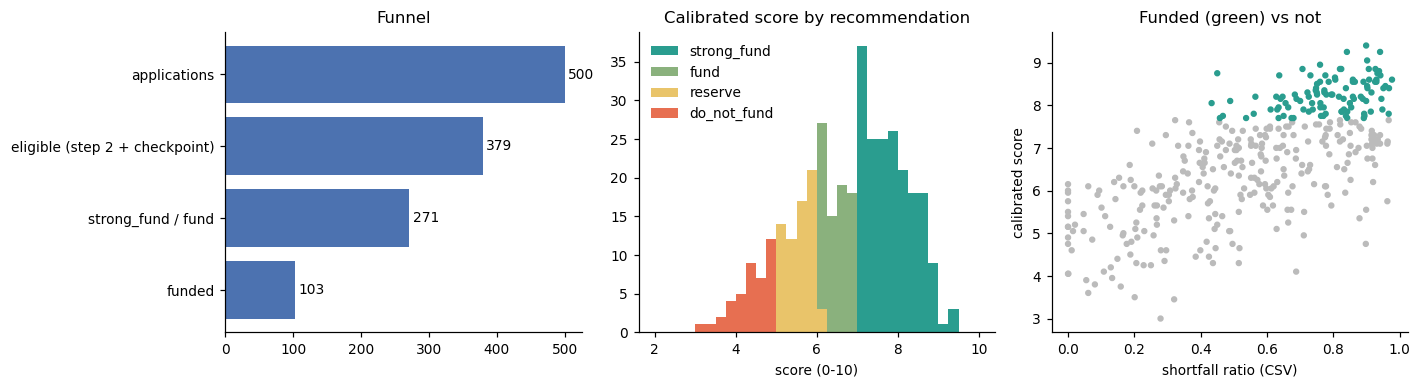

funded by GNI tier: {1: 87, 2: 14, 3: 2} | by study level: {"Master's": 52, "Bachelor's": 28, 'Doctoral': 23}
funded with a conditional award: 9


In [18]:
# --- What the workflow decided: a picture of the funnel and of the scores --------------------------
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
funnel = pd.Series({"applications": len(df), "eligible (step 2 + checkpoint)": len(ELIGIBLE),
                    "strong_fund / fund": int(df.recommendation.isin(["strong_fund", "fund"]).sum()),
                    "funded": int((df.award > 0).sum())})
ax[0].barh(funnel.index[::-1], funnel.values[::-1], color="#4c72b0"); ax[0].set_title("Funnel")
for i, v in enumerate(funnel.values[::-1]): ax[0].text(v + 5, i, str(v), va="center")
E = df.loc[ELIGIBLE]
for cat, col in zip(["strong_fund", "fund", "reserve", "do_not_fund"], ["#2a9d8f", "#8ab17d", "#e9c46a", "#e76f51"]):
    ax[1].hist(E.loc[E.recommendation == cat, "calibrated_score"], bins=np.arange(2, 10.25, 0.25), color=col, label=cat)
ax[1].legend(frameon=False); ax[1].set_title("Calibrated score by recommendation"); ax[1].set_xlabel("score (0-10)")
f = df.award > 0
ax[2].scatter(E.shortfall_ratio, E.calibrated_score, s=10, c=np.where(f[E.index], "#2a9d8f", "#bbbbbb"))
ax[2].set_xlabel("shortfall ratio (CSV)"); ax[2].set_ylabel("calibrated score"); ax[2].set_title("Funded (green) vs not")
plt.tight_layout(); plt.show()
print("funded by GNI tier:", df.loc[f, "gni_tier"].value_counts().sort_index().to_dict(),
      "| by study level:", df.loc[f, "study_level"].value_counts().to_dict())
print("funded with a conditional award:", int((f & df.gate.eq("eligible (conditional)")).sum()))

**Result (first run).** **103 applicants are funded, using the full CHF 500,000** (mean award CHF 4,854; 9 of the
awards are conditional on a permit or on the academic plan).

- **The money runs out inside the strong_fund group.** The last funded calibrated score is 7.7, and **87 applicants
  recommended strong_fund are not funded**. No fund or reserve applicant receives anything.
- **Who is funded:** 87 of the 103 come from low-income countries (GNI tier 1). The funded have a mean need score
  (S1) of 8.7.
- **What decided the cut-off:** within the strong_fund group, the order is the calibrated score. The cut-off therefore
  comes from scores that differ by fractions of a point. A step where the model is least repeatable (see Step 4) has
  a large effect on who gets money.

<div style="border-left:4px solid #e9a23b;background:#fff8ec;padding:10px 14px;margin:6px 0">

**❓ Question for the group** — With 190 strong_fund recommendations and money for about half of them, is "85% of the request, best score first" the
right rule? Compare two alternatives: a lower share (e.g. 60%) to fund more applicants, or funding strong_fund and
fund applicants in proportion to their need. Which is closer to the mission's *"providing them with the means to
pursue their studies"*?
</div>

<div style="border-left:4px solid #7b61ff;background:#f6f4ff;padding:10px 14px;margin:6px 0">

**🧩 In AnythingLLM — the allocation**

The allocation needs the whole pool at once (rank, then spend a budget). It does not belong in a per-applicant flow.
Export the flow's log to a spreadsheet, sort by category and score, and apply the rule with formulas. That is also
where the human sign-off on the final list naturally happens.
</div>

---
## Step 4 — Documentation and reproducibility

*Budget: ~40.6h for a 4-student group.*

### 4.1 Published prompts and settings

The exact prompts are the cells above (`SYSTEM`, `ELIG_RULES`, `READOUT_RULES`, `REC_RULES`, with their JSON schemas).
They are exported, together with the model settings, the weights, the allocation rule and the checkpoint decisions,
to **`prompts_and_settings.json`**.

- **Model and settings:** `gemini-3.5-flash-lite`, temperature 0, seed 2026, JSON output with a response schema,
  maximum 2,048 output tokens.
- **Document parsing:** the full application text goes to the model. We extract no key facts with rules or regular
  expressions, except the completion date, which code reads for the month arithmetic.

### 4.2 Re-run of a 16% sample

80 applicants are drawn at random with seed 2026 and sent through steps 2, 3 and 5 a **second time**, with identical
inputs and settings (`run2`). Steps 3 and 5 are re-run for the sample members who were eligible in run 1. That way
each step's agreement is measured on the same applicants and is not mixed with an earlier step's divergence. The final
agreement puts run 2's decisions into the pool and spends the budget again with the same rule.

In [19]:
# --- Protocol step 4: consistency re-run of a random 16% sample (same prompts, same settings) ---------
rng = np.random.default_rng(SEED)
RERUN_IDS = sorted(rng.choice(df.index.to_numpy(), size=round(RERUN_SHARE * len(df)), replace=False))
RERUN_ELIG = [s for s in RERUN_IDS if s in ELIGIBLE]   # step 3 and 5 are re-run on the same eligible set as run 1,
                                                        # so that each step's agreement is measured on its own
elig2 = run_step("2_eligibility", RERUN_IDS, build_elig, ELIG_SCHEMA, run="run2", label="re-run step 2")
read2 = run_step("3_readout", RERUN_ELIG, build_readout, READOUT_SCHEMA, run="run2", label="re-run step 3")
rec2 = run_step("5_recommendation", RERUN_ELIG, lambda s: build_rec(s, src=read2), REC_SCHEMA, run="run2",
                label="re-run step 5")
print(f"re-run sample: {len(RERUN_IDS)} applicants ({len(RERUN_IDS) / len(df):.0%}); {len(RERUN_ELIG)} of them eligible in run 1")

  re-run step 2: 50/80


  re-run step 3: 50/61
  re-run step 5: 50/61
re-run sample: 80 applicants (16%); 61 of them eligible in run 1


,step,item,n,agreement
0,2 eligibility,H2 verdict,80,1.000
1,2 eligibility,H4 verdict,80,0.975
2,2 eligibility,H5 verdict,80,1.000
3,2 eligibility,H6 verdict,80,1.000
4,2 eligibility,H7 verdict,80,1.000
5,2 eligibility,gate (before human checkpoint),80,0.988
6,2 eligibility,eligible yes/no (flag = undecided),80,0.988
7,3 read-out,"S1 score, exact",61,0.574
8,3 read-out,"S1 score, within 1 point",61,1.000
9,3 read-out,"S2 score, exact",61,0.639


15 of 80 re-run applicants differ in gate, recommendation or funding:


,student_id,gate_run1,gate_run2,rec_run1,rec_run2,ws_run1,ws_run2,funded_run1,funded_run2
0,STU000012,eligible,eligible,strong_fund,fund,7.05,6.50,False,False
1,STU000044,eligible,eligible,strong_fund,strong_fund,7.65,7.70,False,True
2,STU000101,eligible,eligible,strong_fund,fund,7.10,6.85,False,False
3,STU000105,eligible,eligible,strong_fund,strong_fund,7.70,7.60,True,False
4,STU000271,eligible,eligible,fund,reserve,6.55,5.95,False,False
5,STU000277,eligible,eligible,reserve,fund,6.45,6.65,False,False
6,STU000318,ineligible,human checkpoint,-,-,NaN,NaN,False,False
7,STU000323,eligible,eligible,reserve,fund,5.65,6.25,False,False
8,STU000342,eligible,eligible,fund,reserve,6.10,5.85,False,False
9,STU000392,eligible,eligible,reserve,fund,5.95,6.00,False,False


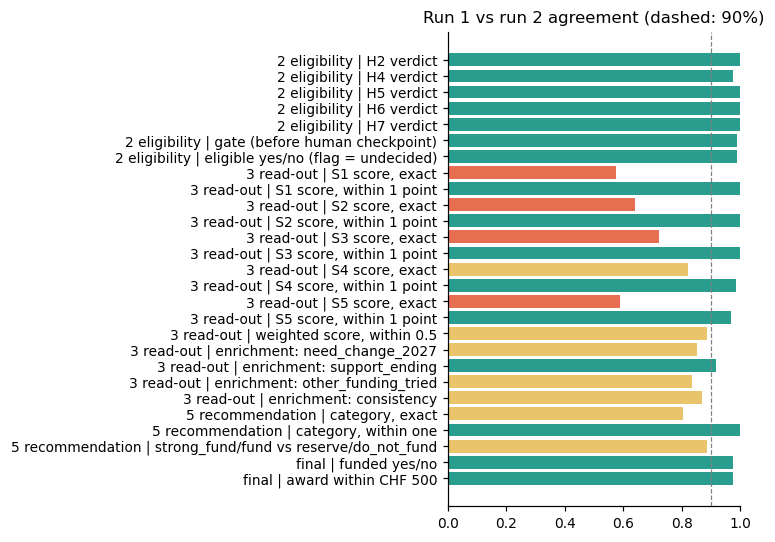

In [20]:
# --- Agreement between run 1 and run 2: per step and final ------------------------------------------
def gate_from(e, sid):
    v = [df.at[sid, "H1"], df.at[sid, "H3"]] + [e[h]["verdict"] for h in LLM_H]
    return ("ineligible" if "fail" in v else "human checkpoint" if "flag" in v
            else "eligible (conditional)" if "conditional" in v else "eligible")
ORDER = ["do_not_fund", "reserve", "fund", "strong_fund"]
rows = []
def add(step, item, a, b, within=None):
    a, b = np.array(list(a), dtype=object), np.array(list(b), dtype=object)
    same = np.array([x == y for x, y in zip(a, b)]) if within is None else np.abs(a.astype(float) - b.astype(float)) <= within
    rows.append({"step": step, "item": item, "n": len(a), "agreement": round(float(same.mean()), 3) if len(a) else np.nan})

S2_IDS = [s for s in RERUN_IDS if s in elig2]
for h in LLM_H:
    add("2 eligibility", f"{h} verdict", [elig[s][h]["verdict"] for s in S2_IDS], [elig2[s][h]["verdict"] for s in S2_IDS])
add("2 eligibility", "gate (before human checkpoint)", [df.at[s, "gate_llm"] for s in S2_IDS], [gate_from(elig2[s], s) for s in S2_IDS])
add("2 eligibility", "eligible yes/no (flag = undecided)", [df.at[s, "gate_llm"] != "ineligible" for s in S2_IDS],
    [gate_from(elig2[s], s) != "ineligible" for s in S2_IDS])

S3_IDS = [s for s in RERUN_ELIG if s in read2]
for k in WEIGHTS:
    a, b = [readout[s][k]["score"] for s in S3_IDS], [read2[s][k]["score"] for s in S3_IDS]
    add("3 read-out", f"{k} score, exact", a, b); add("3 read-out", f"{k} score, within 1 point", a, b, within=1)
ws2 = {s: round(sum(w * read2[s][k]["score"] for k, w in WEIGHTS.items()), 2) for s in S3_IDS}
add("3 read-out", "weighted score, within 0.5", [df.at[s, "weighted_score"] for s in S3_IDS], [ws2[s] for s in S3_IDS], within=0.5)
for c in ["need_change_2027", "support_ending", "other_funding_tried", "consistency"]:
    add("3 read-out", f"enrichment: {c}", [readout[s][c] for s in S3_IDS], [read2[s][c] for s in S3_IDS])

S5_IDS = [s for s in S3_IDS if s in rec2]
r1 = [ORDER.index(rec[s]["recommendation"]) for s in S5_IDS]; r2 = [ORDER.index(rec2[s]["recommendation"]) for s in S5_IDS]
add("5 recommendation", "category, exact", r1, r2); add("5 recommendation", "category, within one", r1, r2, within=1)
add("5 recommendation", "strong_fund/fund vs reserve/do_not_fund", [x >= 2 for x in r1], [x >= 2 for x in r2])

# Final: put run 2's decisions for the sample into the pool and allocate the budget again with the same rule
d2 = df.copy()
for s in S2_IDS:
    if gate_from(elig2[s], s) == "ineligible" and s in ELIGIBLE: d2.at[s, "recommendation"] = "ineligible in run 2"
for s in S5_IDS:
    d2.at[s, "recommendation"] = rec2[s]["recommendation"]
    d2.at[s, "calibrated_score"] = round(ws2[s] + rec2[s]["score_adjustment"], 2)
award2, _ = allocate(d2, ELIGIBLE)
add("final", "funded yes/no", [df.at[s, "award"] > 0 for s in RERUN_IDS], [award2[s] > 0 for s in RERUN_IDS])
add("final", "award within CHF 500", [df.at[s, "award"] for s in RERUN_IDS], [award2[s] for s in RERUN_IDS], within=500)
AGREEMENT = pd.DataFrame(rows)
display(AGREEMENT)

# Every case where the two runs disagree on an outcome that matters
dis = []
for s in RERUN_IDS:
    g1, g2 = df.at[s, "gate_llm"], gate_from(elig2[s], s)
    c1, c2 = (rec[s]["recommendation"] if s in rec else "-"), (rec2[s]["recommendation"] if s in rec2 else "-")
    f1, f2 = df.at[s, "award"] > 0, award2[s] > 0
    if g1 != g2 or c1 != c2 or f1 != f2:
        dis.append({"student_id": s, "gate_run1": g1, "gate_run2": g2, "rec_run1": c1, "rec_run2": c2,
                    "ws_run1": df.at[s, "weighted_score"] if s in ELIGIBLE else np.nan, "ws_run2": ws2.get(s, np.nan),
                    "funded_run1": f1, "funded_run2": f2})
DISAGREE = pd.DataFrame(dis)
print(f"{len(DISAGREE)} of {len(RERUN_IDS)} re-run applicants differ in gate, recommendation or funding:")
display(DISAGREE)
fig, ax = plt.subplots(figsize=(7, 5))
A = AGREEMENT.iloc[::-1]
ax.barh(A.step + " | " + A.item, A.agreement, color=["#2a9d8f" if v >= 0.9 else "#e9c46a" if v >= 0.75 else "#e76f51" for v in A.agreement])
ax.axvline(0.9, ls="--", c="grey", lw=0.8); ax.set_xlim(0, 1); ax.set_title("Run 1 vs run 2 agreement (dashed: 90%)")
plt.tight_layout(); plt.show()

**Findings (first run).** The workflow is **stable early and diverges later**, which is the pattern the protocol
asks us to look for:

- **Step 2, eligibility:** the most stable step. The gate agrees for 79 of 80 applicants (98.8%). The one difference
  (STU000318) is an H4 judgement: run 1 failed it, while run 2 flagged it because a one-off deposit is not a monthly
  gap.
- **Step 3, read-out:**
  - **Exact scores** agree for only 57–82% of applicants, depending on the criterion. S1 is the least stable at 57%,
    and S4, the most rule-like, the most stable at 82%.
  - **Within one point**, agreement is 97–100%, and 89% of weighted scores are within 0.5.
  - **Enrichment columns** agree for 84–92% of applicants.
- **Step 5, recommendation:** the category agrees exactly for 80%, and is never more than one category apart.
- **Final (funded or not):** 97.5% agreement (78 of 80). Two applicants (STU000044, STU000105) swap places right at
  the budget cut-off. Small score differences matter **only near the cut-off**, and that is where a human should look.

> **Caveat.** In the shipped first run, both runs were produced by the same AI agent (Claude), which read the documents
> a second time independently. A live Gemini run at temperature 0 can be more or less stable. **Report the numbers
> from your own Gemini run**, not these.

<div style="border-left:4px solid #e9a23b;background:#fff8ec;padding:10px 14px;margin:6px 0">

**❓ Question for the group** — Which step would you put a second human checkpoint on, given these numbers? A natural candidate is the **budget
cut-off**: every applicant within ±0.3 points of the last funded score gets a human read before the list is final.
</div>

### 4.3 Human checkpoints in the pipeline

1. **Between steps 2 and 3:** every applicant flagged by the eligibility step is read in full by two of us. The
   decisions are recorded in `HUMAN_DECISIONS_FIRST_RUN` and in the column `checkpoint_decision`.
2. **On the conditions:** awards to applicants with a pending permit or a GPA below 2.5 are **conditional**. They are
   paid only after the permit is granted, or the improvement plan is confirmed, at the interview stage.
3. **On the final list:** we sign off the allocation and look at the cases near the budget cut-off.

### 4.4 Which decisions are the LLM's, and which are ours

| Decision | Made by | Where |
|---|---|---|
| Steps of the pipeline and their link to the call | humans (us) | Step 1.1 |
| Interpretation of each hard criterion (CHF 6,000, GPA exception, H4 evidence) | humans (us) | `ELIG_RULES` |
| Verdict and evidence per hard criterion, per applicant | **LLM** | step 2 |
| Gate (verdicts → eligible/conditional/checkpoint/ineligible) | code (our rule) | `GATE` |
| Flagged cases | humans (us) | checkpoint |
| Scoring anchors and weights | humans (us) / call | `READOUT_RULES`, `WEIGHTS` |
| Scores S1–S5 and the 7 enrichment columns, per applicant | **LLM** | step 3 |
| Cohort and peers | code (our definition) | step 4 |
| Score adjustment (±1 max), category, rationale | **LLM**, inside our rules | step 5 |
| Request, award share, order, budget | code (our rule) | allocation |

### 4.5 Exporting the workflow to AnythingLLM

The cell below writes **`anythingllm_flow_eduall.json`**: a flow with a Flow Variables block (`student_id`, `record`,
`application`, `weights`, `peers`) and three LLM Instruction blocks (`eligibility` → `readout` → `recommendation`)
whose instructions are **exactly our prompts**, with `${variables}` in place of Python. It also writes an example
input for one applicant.

How to use it:

1. **Rebuild in the UI.** Recommended, and it works on every version. *Agent Skills → Create Flow*: fill in Flow
   Information, add the five variables, add three LLM Instruction blocks, and copy each `instruction` and
   `resultVariable` from the JSON into the block. On Desktop 1.8.1+, replace the `application` variable with a
   **Read File** block, and add a **Write File** block at the end for the log.
2. **Import the file directly.** AnythingLLM keeps each flow as `<uuid>.json` in the `plugins/agent-flows/` folder of
   its storage directory. Copying the file there (with a new uuid as the file name) and reloading makes it appear
   under Agent Skills. It uses only block types that every version accepts.
3. **Run it.** In a workspace chat whose agent LLM is Gemini: *"@agent run the EduAll grant screening flow for
   STU000001 with this record and application: …"*. For all applicants, repeat per applicant, or loop over them
   with the AnythingLLM developer API.

In [21]:
# --- The same workflow as an AnythingLLM Agent Flow (importable skeleton) ---------------------------
# Blocks used: Flow Information + Flow Variables ("start") and three LLM Instruction blocks ("llmInstruction").
# The prompts are the ones above, with ${variables} instead of Python f-strings. Arithmetic steps (need, weighted score,
# peers, budget) are NOT LLM work: they are passed in as variables computed beforehand (see the markdown above).
flow = {"name": "EduAll grant screening - one applicant",
        "description": "Steps 2, 3 and 5 of our LLM workflow for one applicant: eligibility, need/merit read-out, recommendation.",
        "active": True,
        "steps": [
          {"type": "start", "config": {"variables": [
              {"name": "student_id", "value": "", "type": "required", "description": "e.g. STU000001"},
              {"name": "record", "value": "", "type": "required",
               "description": "CSV row + derived figures (need_2027, shortfall_ratio, months_in_grant) as JSON"},
              {"name": "application", "value": "", "type": "required", "description": "full text of <student_id>_application.md"},
              {"name": "weights", "value": json.dumps(WEIGHTS), "type": "static", "description": "call weights S1-S5"},
              {"name": "peers", "value": "[]", "type": "optional", "description": "peer rows from step 4 (JSON)"}]}},
          {"type": "llmInstruction", "config": {"resultVariable": "eligibility", "instruction":
              SYSTEM + "\n\nSTEP 2 - ELIGIBILITY EXTRACTION\n\n" + ELIG_RULES + "\nJSON schema: " + json.dumps(ELIG_SCHEMA)
              + "\n\nAPPLICANT RECORD (${student_id})\n${record}\n\n### Application document\n${application}"}},
          {"type": "llmInstruction", "config": {"resultVariable": "readout", "instruction":
              SYSTEM + "\n\nIf any verdict in this eligibility result is \"fail\", answer only {\"skipped\": true}.\n"
              "ELIGIBILITY RESULT (step 2): ${eligibility}\n\nSTEP 3 - NEED/MERIT READ-OUT\n\n" + READOUT_RULES
              + "\nJSON schema: " + json.dumps(READOUT_SCHEMA) + "\n\nAPPLICANT RECORD (${student_id})\n${record}\n\n### Application document\n${application}"}},
          {"type": "llmInstruction", "config": {"resultVariable": "recommendation", "instruction":
              SYSTEM + "\n\nIf the read-out is {\"skipped\": true}, answer {\"recommendation\": \"ineligible\"}.\n"
              "STEP 5 - RECOMMENDATION DRAFTING\n\n" + REC_RULES + "\nWeighted score = sum of the S scores in ${readout} times ${weights}."
              + "\nJSON schema: " + json.dumps(REC_SCHEMA) + "\n\nRead-out (step 3): ${readout}\nPeers (step 4): ${peers}"
              + "\n\nAPPLICANT RECORD (${student_id})\n${record}"}}]}
json.dump(flow, open("anythingllm_flow_eduall.json", "w"), ensure_ascii=False, indent=1)
print("steps:", [s["type"] for s in flow["steps"]], "| instruction lengths:",
      [len(s["config"].get("instruction", "")) for s in flow["steps"][1:]])
# A ready-made input for one applicant, to paste into the flow's variables when testing it in AnythingLLM
EXAMPLE = ELIGIBLE[0]
row = df.loc[EXAMPLE, [c for c in df.columns if c in CSV_COLUMNS or c in DERIVED]].to_dict()
json.dump({"student_id": EXAMPLE, "record": json.dumps({k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}, ensure_ascii=False),
           "application": document(EXAMPLE), "peers": peer_context(EXAMPLE)},
          open(f"anythingllm_example_input_{EXAMPLE}.json", "w"), ensure_ascii=False, indent=1)
print("example input written for", EXAMPLE)

steps: ['start', 'llmInstruction', 'llmInstruction', 'llmInstruction'] | instruction lengths: [4440, 5241, 2371]
example input written for STU000001


In [22]:
# --- Exports --------------------------------------------------------------------------------------
NEW_COLS = (["H1", "H2", "H2_evidence", "H3", "H4", "H4_evidence", "H5", "H5_evidence", "H6", "H6_evidence", "H7",
             "H7_evidence", "eligibility_summary", "gate_llm", "gate", "checkpoint_decision"]
            + [c for s in WEIGHTS for c in (s, s + "_evidence")] + ENRICH
            + ["weighted_score", "cohort", "cohort_percentile", "score_adjustment", "adjustment_reason",
               "recommendation", "rationale", "calibrated_score", "request", "award", "funding_rank"])
df["status"] = np.select([df.award > 0, df.gate.eq("ineligible")],
                         [np.where(df.gate.eq("eligible (conditional)"), "funded (conditional)", "funded"), "ineligible"],
                         "eligible, not funded")
def reason(r):
    if r.gate == "ineligible": return r.checkpoint_decision or r.eligibility_summary
    if r.award > 0: return f"{r.recommendation} (rank {int(r.funding_rank)}), {int(SHARE[r.recommendation] * 100)}% of request"
    if r.recommendation == "do_not_fund": return "do_not_fund: " + r.rationale
    return f"{r.recommendation}: budget exhausted before this rank" if r.request * SHARE.get(r.recommendation, 0) >= MIN_AWARD \
        else f"{r.recommendation}: request below CHF {MIN_AWARD:,}"
df["reason"] = df.apply(reason, axis=1)
enriched = df[CSV_COLUMNS + DERIVED + [c for c in NEW_COLS if c not in CSV_COLUMNS] + ["status", "reason"]]
enriched.to_csv("enriched_applications.csv", index=False)
PROG = ["student_id", "study_level", "study_mode", "residency_permit", "gni_tier", "geographic_region", "gpa",
        "academic_standing", "need_2027", "shortfall_ratio", "family_household_income_chf", "savings_chf",
        "external_scholarship_amount_chf", "months_in_grant", "H1", "H2", "H3", "H4", "H5", "H6", "H7", "gate_llm",
        "gate", "S1", "S2", "S3", "S4", "S5", "weighted_score", "need_change_2027", "support_ending", "consistency",
        "cohort", "cohort_percentile", "score_adjustment", "calibrated_score", "recommendation", "request",
        "funding_rank", "award", "status", "reason"]
df[PROG].to_csv("decision_progression.csv", index=False)
df.loc[df.award > 0, PROG].sort_values("funding_rank").to_csv("final_allocation.csv", index=False)
AGREEMENT.to_csv("rerun_agreement.csv", index=False); DISAGREE.to_csv("rerun_disagreements.csv", index=False)
json.dump({"model": MODEL, "temperature": TEMPERATURE, "seed": SEED, "max_output_tokens": MAX_OUTPUT_TOKENS,
           "response_format": "application/json with response schema", "backend_used": BACKEND,
           "first_run_producer": "claude-opus-5-5 acting as the LLM endpoint (stored in llm_responses_firstrun.jsonl)",
           "system_instruction": SYSTEM,
           "step2_eligibility": {"rules": ELIG_RULES, "schema": ELIG_SCHEMA},
           "step3_readout": {"rules": READOUT_RULES, "schema": READOUT_SCHEMA, "weights": WEIGHTS},
           "step4_peers": {"cohort": "gni_tier | study_level", "n_peers": N_PEERS, "distance": "shortfall_ratio"},
           "step5_recommendation": {"rules": REC_RULES, "schema": REC_SCHEMA},
           "allocation": {"budget": BUDGET, "min_award": MIN_AWARD, "savings_reserve": RESERVE_SAVINGS,
                          "share_of_request": SHARE, "level_caps_per_year": CAP},
           "human_checkpoint": {"decisions": {k: v[0] for k, v in HUMAN_DECISIONS.items()}, "undecided_rule": UNDECIDED_RULE},
           "rerun": {"share": RERUN_SHARE, "sample_seed": SEED, "n": len(RERUN_IDS)}},
          open("prompts_and_settings.json", "w"), ensure_ascii=False, indent=1)
print(df.status.value_counts().to_dict())
for fn in ["enriched_applications.csv", "decision_progression.csv", "final_allocation.csv", "rerun_agreement.csv",
           "rerun_disagreements.csv", "prompts_and_settings.json", "workflow_log.jsonl"]:
    print(f"{fn:32s} {os.path.getsize(fn) / 1024:8.0f} KB")

{'eligible, not funded': 276, 'ineligible': 121, 'funded': 94, 'funded (conditional)': 9}
enriched_applications.csv             629 KB
decision_progression.csv              149 KB
final_allocation.csv                   30 KB
rerun_agreement.csv                     1 KB
rerun_disagreements.csv                 1 KB
prompts_and_settings.json              13 KB
workflow_log.jsonl                   1185 KB


### 4.6 Summary of our decision path

1. **500 applications → 379 eligible** after the LLM eligibility step and our checkpoint, 31 of them with a
   condition. 121 are ineligible: 117 fail at least one criterion (standing 63, need 61, Permit C with significant
   resources 19, some failing more than one), and 4 are excluded at the checkpoint.
2. **Read-out:** S1–S5 with evidence, plus 7 new columns from the documents. The text changes the picture for many
   applicants: 115 need increases and 52 major CSV/document discrepancies.
3. **Peers:** 9 cohorts (GNI tier × study level), 4 peers each.
4. **Recommendations:** 190 strong_fund, 81 fund, 67 reserve, 41 do_not_fund (52 scores adjusted, 12 category moves).
5. **Allocation: 103 awards, CHF 500,000.** All go to strong_fund applicants, and 87 of them are from low-income
   countries.
6. **Re-run (16%):** eligibility 98.8% stable, scores ±1 stable, categories 80% exact, final funding 97.5%.
   Divergence concentrates at the budget cut-off.

**Output files** (next to this notebook):

- `enriched_applications.csv`: the 500 CSV rows plus every new column.
- `decision_progression.csv`: all applicants, every step.
- `final_allocation.csv`: the funded applicants, in funding order.
- `rerun_agreement.csv` and `rerun_disagreements.csv`.
- `prompts_and_settings.json`.
- `workflow_log.jsonl`: one line per applicant and step.
- `anythingllm_flow_eduall.json`.

### Sources

- AnythingLLM documentation: [Agent Flows overview](https://docs.anythingllm.com/agent-flows/overview),
  [Getting started](https://docs.anythingllm.com/agent-flows/getting-started),
  [Default blocks](https://docs.anythingllm.com/agent-flows/blocks/default-blocks),
  [LLM Instruction](https://docs.anythingllm.com/agent-flows/blocks/llm-instruction),
  [API Call](https://docs.anythingllm.com/agent-flows/blocks/api-call),
  [Read File](https://docs.anythingllm.com/agent-flows/blocks/read-file),
  [Write File](https://docs.anythingllm.com/agent-flows/blocks/write-file),
  [Tutorial](https://docs.anythingllm.com/agent-flows/tutorial-hackernews),
  [Using agents](https://docs.anythingllm.com/agent/usage/overview);
  loop/if-else feature request: [GitHub issue #6445](https://github.com/Mintplex-Labs/anything-llm/issues/6445).
- Gemini API: [models](https://ai.google.dev/gemini-api/docs/models),
  [text generation](https://ai.google.dev/gemini-api/docs/text-generation),
  [structured output](https://ai.google.dev/gemini-api/docs/structured-output),
  [rate limits](https://ai.google.dev/gemini-api/docs/rate-limits).